In [4]:
!pip -q install ultralytics pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 17.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 3.8 MB/s eta 0:00:00


In [5]:
import os
import zipfile
import shutil
import yaml
import torch

from pathlib import Path
from ultralytics import RTDETR

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [16]:
from pathlib import Path

# Update these paths with your actual Kaggle paths
IMAGE_DIR = Path("/kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/images")
LABEL_DIR = Path("/kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/labels")
YAML_PATH = Path("/kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/data.yaml")
MODEL_PATH = "/kaggle/input/datasets/ashrifrahmanarian/rtdetr-c2a-finetuned/flood_finetuned_best.pt"

# Dataset root
DATASET_ROOT = IMAGE_DIR.parent.parent

print("Images:", IMAGE_DIR)
print("Labels:", LABEL_DIR)
print("YAML:", YAML_PATH)
print("Model:", MODEL_PATH)

Images: /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/images
Labels: /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/labels
YAML: /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/data.yaml
Model: /kaggle/input/datasets/ashrifrahmanarian/rtdetr-c2a-finetuned/flood_finetuned_best.pt


In [7]:
assert IMAGE_DIR.is_dir(), "Image folder not found!"
assert LABEL_DIR.is_dir(), "Label folder not found!"
assert YAML_PATH.is_file(), "data.yaml not found!"
assert Path(MODEL_PATH).is_file(), "Model not found!"

images = sorted([
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
])

labels = sorted(LABEL_DIR.glob("*.txt"))

print("Total images:", len(images))
print("Total label files:", len(labels))
print("All paths verified!")

Total images: 27
Total label files: 27
All paths verified!


In [8]:
import yaml

DATA_YAML = "/kaggle/working/data_external_test.yaml"

config = {
    "path": str(DATASET_ROOT),
    "train": str(IMAGE_DIR),
    "val": str(IMAGE_DIR),
    "test": str(IMAGE_DIR),
    "nc": 1,
    "names": {0: "human"}
}

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(open(DATA_YAML).read())

path: /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external
train: /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/images
val: /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/images
test: /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/images
nc: 1
names:
  0: human



In [9]:
image_stems = {p.stem for p in images}
label_stems = {p.stem for p in labels}

print("Total images:", len(images))
print("Total label files:", len(labels))
print("Images without labels:", image_stems - label_stems)
print("Labels without images:", label_stems - image_stems)

assert len(images) > 0, "No images found"
assert not (label_stems - image_stems), "Some labels have no matching image"

# Missing labels are acceptable only for verified images with no humans.

Total images: 27
Total label files: 27
Images without labels: set()
Labels without images: set()


In [17]:
from ultralytics import RTDETR
import torch

DEVICE = 0 if torch.cuda.is_available() else "cpu"
IMGSZ = 640  # Use your original evaluation image size

model = RTDETR(MODEL_PATH)

print("Device:", DEVICE)
print("Model classes:", model.names)

assert len(model.names) == 1, "Check the model class mapping"

Device: 0
Model classes: {0: 'human'}


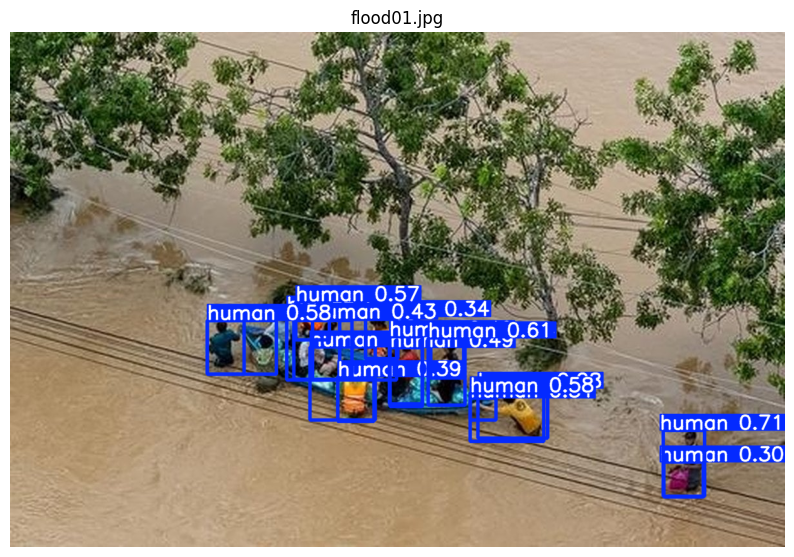

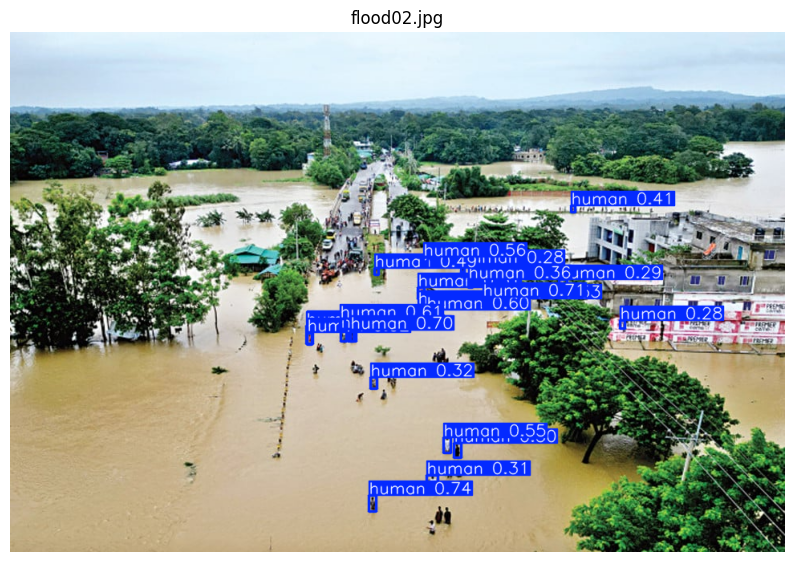

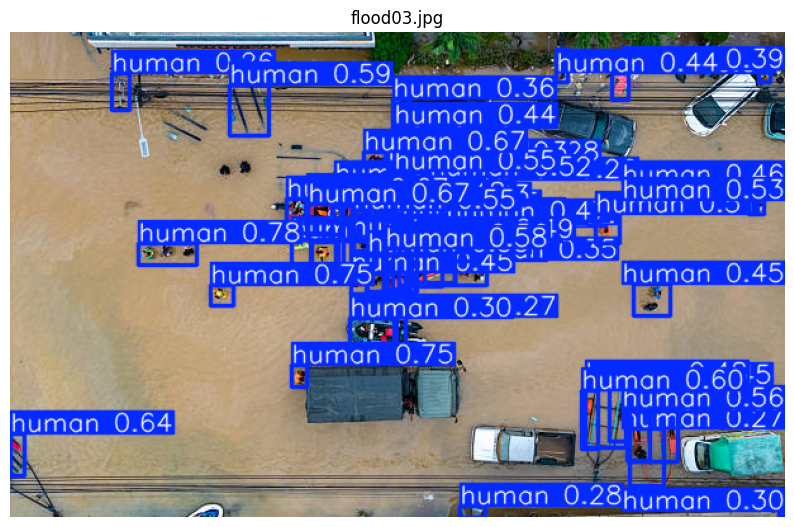

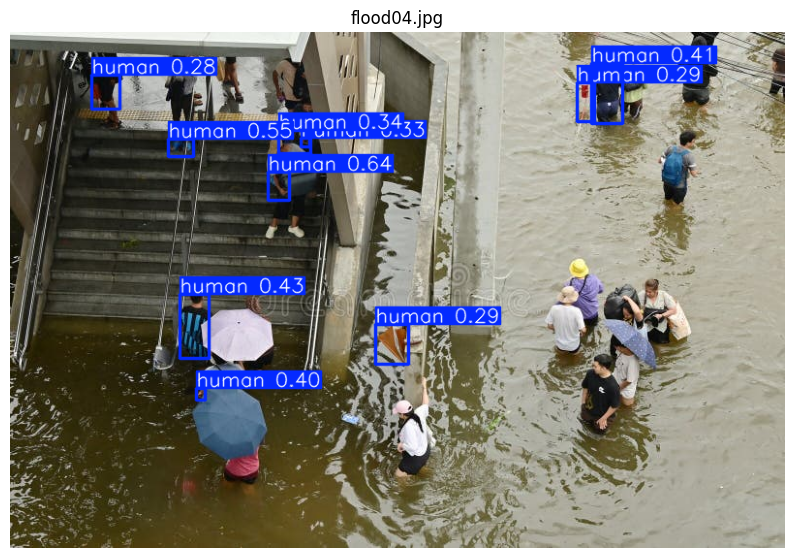

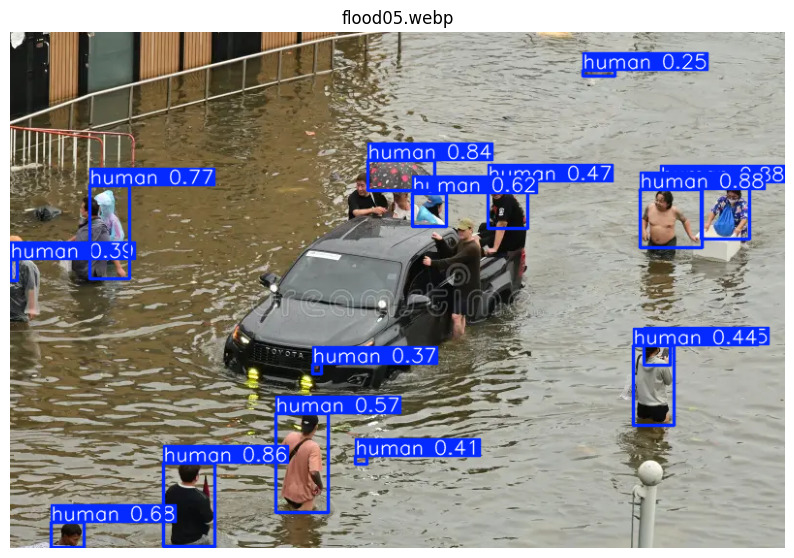

In [18]:
import matplotlib.pyplot as plt

results = model.predict(
    source=[str(p) for p in images[:5]],
    imgsz=IMGSZ,
    conf=0.25,
    device=DEVICE,
    verbose=False
)

for result in results:
    plt.figure(figsize=(10, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.title(Path(result.path).name)
    plt.axis("off")
    plt.show()

In [19]:
predictions = model.predict(
    source=str(IMAGE_DIR),
    imgsz=IMGSZ,
    conf=0.25,
    device=DEVICE,
    save=True,
    save_txt=True,
    save_conf=True,
    project="/kaggle/working/RTDETR_Results",
    name="predictions",
    exist_ok=True,
    verbose=False
)

print("Images processed:", len(predictions))

Results saved to /kaggle/working/RTDETR_Results/predictions
27 labels saved to /kaggle/working/RTDETR_Results/predictions/labels
Images processed: 27


In [20]:
metrics = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=IMGSZ,
    batch=4,
    conf=0.001,
    device=DEVICE,
    plots=True,
    project="/kaggle/working/RTDETR_Results",
    name="evaluation",
    exist_ok=True
)

precision = float(metrics.box.mp)
recall = float(metrics.box.mr)
map50 = float(metrics.box.map50)
map5095 = float(metrics.box.map)

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0.0
)

print(f"Precision:       {precision:.4f}")
print(f"Recall:          {recall:.4f}")
print(f"F1 (summary):    {f1:.4f}")
print(f"mAP@0.5:         {map50:.4f}")
print(f"mAP@0.5:0.95:    {map5095:.4f}")

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
rt-detr-l summary (fused): 310 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.2 ms, read: 219.4±111.9 MB/s, size: 113.8 KB)
val: Scanning /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/labels... 27 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 27/27 474.0it/s 0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.0it/s 1.8s0.2s
                   all         27        288      0.302      0.237      0.151     0.0738
Speed: 1.9ms preprocess, 49.6ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /kaggle/working/RTDETR_Results/evaluation
Precision:       0.3017
Recall:          0.2370
F1 (

In [21]:
import pandas as pd

summary = pd.DataFrame([{
    "Dataset": "Real Flood UAV",
    "Images": len(images),
    "Precision": precision,
    "Recall": recall,
    "F1_summary": f1,
    "mAP50": map50,
    "mAP50_95": map5095
}])

summary.to_csv(
    "/kaggle/working/RTDETR_Results/metrics_summary.csv",
    index=False
)

display(summary)

,Dataset,Images,Precision,Recall,F1_summary,mAP50,mAP50_95
0,Real Flood UAV,27,0.301671,0.236997,0.265452,0.151302,0.073773


In [ ]:
PLOT_DIR = Path(
    "/kaggle/working/RTDETR_Results/evaluation"
)

plot_files = sorted(PLOT_DIR.glob("*.png"))

for p in plot_files:
    print(p.name)
    plt.figure(figsize=(9, 6))
    plt.imshow(plt.imread(p))
    plt.axis("off")
    plt.show()

In [ ]:
import shutil

shutil.make_archive(
    "/kaggle/working/RTDETR_External_Validation",
    "zip",
    "/kaggle/working/RTDETR_Results"
)

print("Saved: /kaggle/working/RTDETR_External_Validation.zip")